In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score , classification_report
from sklearn.metrics import confusion_matrix

In [4]:
sns.set_style("whitegrid")
pd.set_option("display.max_colwidth",200)

In [5]:
fake = pd.read_csv(r"Fake.csv")
true = pd.read_csv(r"True.csv")

In [6]:
fake["label"]=0
true["label"]=1

In [7]:
print("Fake shape:",fake.shape)
print("True shape:",true.shape)

Fake shape: (23481, 5)
True shape: (21417, 5)


In [9]:
df=pd.concat([fake,true],ignore_index = True)
df = df.sample(frac=1,random_state = 42)
df.head()

,title,text,subject,date,label
22216,Ben Stein Calls Out 9th Circuit Court: Committed a ‘Coup d’état’ Against the Constitution,"21st Century Wire says Ben Stein, reputable professor from, Pepperdine University (also of some Hollywood fame appearing in TV shows and films such as Ferris Bueller s Day Off) made some provocati...",US_News,"February 13, 2017",0
27917,Trump drops Steve Bannon from National Security Council,"WASHINGTON (Reuters) - U.S. President Donald Trump removed his chief strategist Steve Bannon from the National Security Council on Wednesday, reversing his controversial decision early this year t...",politicsNews,"April 5, 2017",1
25007,Puerto Rico expects U.S. to lift Jones Act shipping restrictions,"(Reuters) - Puerto Rico Governor Ricardo Rossello said on Wednesday he expected the federal government to waive the Jones Act, which would lift restrictions on ships that can provide aid to the is...",politicsNews,"September 27, 2017",1
1377,OOPS: Trump Just Accidentally Confirmed He Leaked Israeli Intelligence To Russia (VIDEO),"On Monday, Donald Trump once again embarrassed himself and his country by accidentally revealing the source of the extremely classified information he leaked to Russia earlier this month.While it ...",News,"May 22, 2017",0
32476,Donald Trump heads for Scotland to reopen a golf resort,"GLASGOW, Scotland (Reuters) - Most U.S. presidential candidates go abroad to sharpen their foreign policy credentials. Donald Trump arrives in Scotland on Friday to reopen a golf resort. The presu...",politicsNews,"June 24, 2016",1


In [10]:
print(df.shape)
df.info()
print()
print("Missing values:",df.isnull().sum())
print()
print("Duplicate values:",df.duplicated().sum())
print()
print("Duplicate values in text field",df["text"].duplicated().sum())
print()
print("Empty texts:", (df["text"].str.strip() == "").sum())

(44898, 5)
<class 'pandas.core.frame.DataFrame'>
Index: 44898 entries, 22216 to 15795
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    44898 non-null  object
 1   text     44898 non-null  object
 2   subject  44898 non-null  object
 3   date     44898 non-null  object
 4   label    44898 non-null  int64 
dtypes: int64(1), object(4)
memory usage: 2.1+ MB

Missing values: title      0
text       0
subject    0
date       0
label      0
dtype: int64

Duplicate values: 209

Duplicate values in text field 6252

Empty texts: 631


In [11]:
empty_mask = df["text"].str.strip()==""
print(df[empty_mask]["label"].value_counts())
print(df[empty_mask][["title","label"]].head())

label
0    630
1      1
Name: count, dtype: int64
                                                                                       title  \
12038                                          WHERE’S HILLARY? CLINTON SPOTTED Dining Alone   
12750              WHOA! RUSH LIMBAUGH RIPS Into Republicans Who Don’t Support Trump [Audio]   
13008       HILLARY TAKES CREDIT For The Arab Spring Disaster…AND SHE WANTS TO BE PRESIDENT?   
11478  CHILLING! FOX REPORTER JAMES ROSEN Recounts Being Spied on by the Obama Mafia [Video]   
11854                                                          LIVE FEED: INAUGURATION 2017!   

       label  
12038      0  
12750      0  
13008      0  
11478      0  
11854      0  


label
0    23481
1    21417
Name: count, dtype: int64


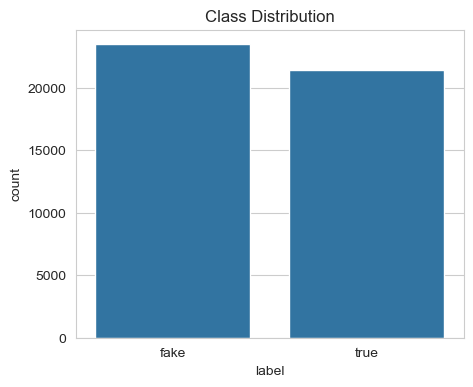

In [13]:
print(df["label"].value_counts())
plt.figure(figsize=(5,4))
sns.countplot(x='label',data =df)
plt.xticks([0,1],["fake","true"])
plt.title("Class Distribution")
plt.show()

         count        mean         std  min    25%    50%    75%     max
label                                                                   
0      23481.0  423.197905  408.388890  0.0  240.0  363.0  506.0  8135.0
1      21417.0  385.640099  274.006204  0.0  148.0  359.0  525.0  5172.0


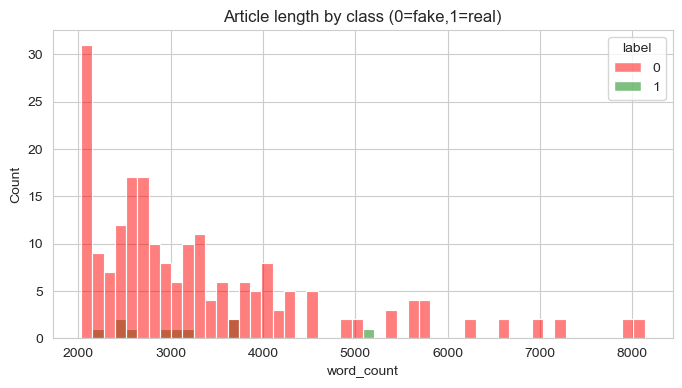

In [14]:
df["word_count"] = df["text"].str.split().str.len()
print(df.groupby("label")["word_count"].describe())

plt.figure(figsize=(8,4))
sns.histplot(data=df[df["word_count"]>2000],x='word_count',hue='label',bins=50, palette=['red','green'])
plt.title("Article length by class (0=fake,1=real)")
plt.show()

In [15]:
print(pd.crosstab(df["subject"],df['label']))

label               0      1
subject                     
Government News  1570      0
Middle-east       778      0
News             9050      0
US_News           783      0
left-news        4459      0
politics         6841      0
politicsNews        0  11272
worldnews           0  10145


In [16]:
df["has_reuters"]= df["text"].str.contains(r"\(Reuters\)",regex = True)
print(df.groupby("label")["has_reuters"].mean())

label
0    0.000383
1    0.992062
Name: has_reuters, dtype: float64


In [17]:
print("REAL examples:")
for t in df[df["label"]==1]["text"].head(3):
  print("-",t[:150])
print("FAKE examples:")
for t in df[df["label"]==0]["text"].head(3):
  print("-",t[:150])

REAL examples:
- WASHINGTON (Reuters) - U.S. President Donald Trump removed his chief strategist Steve Bannon from the National Security Council on Wednesday, reversin
- (Reuters) - Puerto Rico Governor Ricardo Rossello said on Wednesday he expected the federal government to waive the Jones Act, which would lift restri
- GLASGOW, Scotland (Reuters) - Most U.S. presidential candidates go abroad to sharpen their foreign policy credentials. Donald Trump arrives in Scotlan
FAKE examples:
- 21st Century Wire says Ben Stein, reputable professor from, Pepperdine University (also of some Hollywood fame appearing in TV shows and films such as
- On Monday, Donald Trump once again embarrassed himself and his country by accidentally revealing the source of the extremely classified information he
- On Wednesday, Democrats took a powerful stance against the GOP s refusal to vote on gun control measures by staging a sit-in. While Republican politic


In [18]:
df = df.drop(columns = ["subject","date","has_reuters"],errors = 'ignore')

before = len(df)
df = df[df["text"].str.strip().str.len()>50]
print("Removed short/empty:",before - len(df))

before = len(df)
df.drop_duplicates(subset="text")
print("Removed duplicates:",before-len(df))

def clean_text(text):
  text = str(text)
  text = re.sub(r"^.{0,100}?\(Reuters\)\s*-?\s*","",text)
  text = text.lower()
  text = re.sub(r"hhtp\S+"," ",text)
  text = re.sub(r"[^a-z\s]"," ",text)
  text = re.sub(r"\s+"," ",text).strip()
  return text

Removed short/empty: 842
Removed duplicates: 0


In [20]:
df["text"]= df["text"].apply(clean_text)
df["title"]=df["title"].apply(clean_text)
df["content"]=df["title"]+ " " +df["text"]

In [21]:
print("Remaining rows:",len(df))
print(df["label"].value_counts())

Remaining rows: 44056
label
0    22640
1    21416
Name: count, dtype: int64


In [22]:
print(df.shape)
df[["content","label"]].head()

(44056, 5)


,content,label
22216,ben stein calls out th circuit court committed a coup d tat against the constitution st century wire says ben stein reputable professor from pepperdine university also of some hollywood fame appea...,0
27917,trump drops steve bannon from national security council u s president donald trump removed his chief strategist steve bannon from the national security council on wednesday reversing his controver...,1
25007,puerto rico expects u s to lift jones act shipping restrictions puerto rico governor ricardo rossello said on wednesday he expected the federal government to waive the jones act which would lift r...,1
1377,oops trump just accidentally confirmed he leaked israeli intelligence to russia video on monday donald trump once again embarrassed himself and his country by accidentally revealing the source of ...,0
32476,donald trump heads for scotland to reopen a golf resort most u s presidential candidates go abroad to sharpen their foreign policy credentials donald trump arrives in scotland on friday to reopen ...,1


In [ ]:
x=df["content"]
y=df["label"]

x_train , x_test , y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [24]:
print("Train size:",len(x_train))
print("Test size:",len(x_test))

Train size: 35244
Test size: 8812


In [27]:
model = Pipeline([
    ("tfidf",TfidfVectorizer(max_features=50000,ngram_range=(1,2),stop_words="english")),
    ("clf",LogisticRegression(max_iter=1000)),
])

In [28]:
model.fit(x_train,y_train)
print("Training done.")

Training done.


In [29]:
prediction = model.predict(x_test)
print("Accuracy score:",accuracy_score(y_test,prediction))
print()
print(classification_report(y_test,prediction,target_names=["Fake","Real"]))

Accuracy score: 0.9838856105310939

              precision    recall  f1-score   support

        Fake       0.99      0.98      0.98      4528
        Real       0.98      0.99      0.98      4284

    accuracy                           0.98      8812
   macro avg       0.98      0.98      0.98      8812
weighted avg       0.98      0.98      0.98      8812



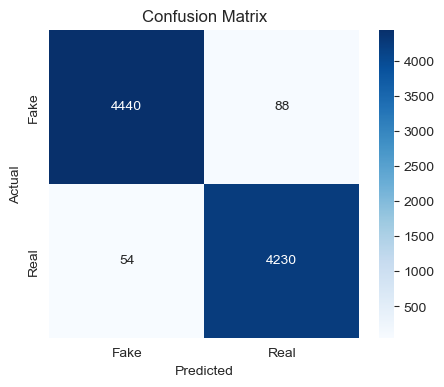

In [30]:
cm = confusion_matrix(y_test,prediction)
plt.figure(figsize=(5,4))
sns.heatmap(cm , annot = True,fmt = "d",cmap ='Blues',xticklabels=["Fake","Real"],yticklabels=["Fake","Real"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


In [31]:
tfidf = model.named_steps["tfidf"]
clf = model.named_steps["clf"]

words = np.array(tfidf.get_feature_names_out())
coefs = clf.coef_[0]

top_real = words[np.argsort(coefs)[-20:]]
top_fake = words[np.argsort(coefs)[:-20]]

print("Top words for REAL:",list(top_real))
print()
print("Top words for FAKE:",list(top_fake))

Top words for REAL: ['senate', 'comment', 'reporters', 'spokesman', 'democratic', 'told reuters', 'president barack', 'presidential', 'said statement', 'nov', 'minister', 'monday', 'friday', 'thursday', 'republican', 'tuesday', 'wednesday', 'reuters', 'president donald', 'said']

Top words for FAKE: ['video', 'just', 'hillary', 'president trump', 'gop', 'read', 'image', 'featured image', 'featured', 'watch', 'obama', 'mr', 'america', 'wire', 'like', 'com', 'getty', 'getty images', 'breaking', 'president obama', 'sen', 'rep', 'american', 'https', 'images', 'isis', 'twitter com', 'didn', 'pic', 'pic twitter', 'doesn', 'fact', 'breitbart', 'know', 'really', 'daily', 'today', 'isn', 'press', 'fox', 'actually', 'terror', 'st century', 'century wire', 'entire', 'americans', 'news', 'money', 'story', 'according', 'went', 'way', 'reportedly', 'black', 'muslim', 'reports', 'thing', 'st', 'time', 'right', 'liberal', 'cnn', 'mail', 'don', 'wasn', 'gov', 'morning', 'racist', 'll', 'reason', 'centu

In [32]:
import joblib , os
os.makedirs("models",exist_ok=True)
joblib.dump(model,"models/fake_news_model.pkl")

['models/fake_news_model.pkl']